# 04 – Nội dung 6: Đánh giá hệ thống

Công việc 6.1 (đánh giá mô hình dự đoán) và 6.2 (đánh giá hiệu quả hỗ trợ ra quyết định của DSS).

> **Quyền riêng tư:** `customer_id` là mã giả danh (`KH_` + HMAC, không suy ngược được nếu không có khóa); dữ liệu không còn số điện thoại hay họ tên. Notebook chỉ hiển thị số liệu tổng hợp và mã đã che.

> **Tái lập:** chạy `python omni_dss/train_pipeline.py` trước (sinh mô hình và các file kết quả trong `omni_dss/saved_models/`).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
LEVEL_COLOR = {"CRITICAL": "#d03b3b", "HIGH": "#eb6834", "MEDIUM": "#eda100", "LOW": "#1baf7a"}
from omni_dss.ml import feature_engineering as fe
from omni_dss.ml.config import SAVED_MODELS_DIR
SM = Path(SAVED_MODELS_DIR)
def load(name): return json.load(open(SM / name, encoding="utf-8"))

Hai câu hỏi đánh giá:
- **CV 6.1:** mô hình dự đoán tốt đến đâu, ổn định không, và so với cách đơn giản thì sao?
- **CV 6.2:** các cảnh báo của DSS có nhắm đúng đối tượng không?

Toàn bộ đánh giá dùng dữ liệu **chưa thấy khi huấn luyện** (tập kiểm tra out-of-time và các kỳ walk-forward), đối chiếu với hành vi mua thực tế.

Mã nguồn: `omni_dss/ml/evaluate_models.py` (6.1), `omni_dss/ml/evaluate_dss.py` (6.2), `omni_dss/ml/walk_forward.py`.

In [2]:
me, de, wf, rp = load("model_evaluation.json"), load("dss_evaluation.json"), load("walk_forward.json"), load("repeat_metrics.json")
ts = me["test_set"]
print(f"Tập kiểm tra out-of-time: {ts['customers']:,} khách | tỷ lệ churn {ts['churn_rate']:.1%} | cửa sổ kết quả {ts['outcome_window']['days']} ngày | mô hình {ts['model']}")

Tập kiểm tra out-of-time: 2,724 khách | tỷ lệ churn 96.2% | cửa sổ kết quả 8.56 ngày | mô hình XGBoost


## 1. CV 6.1 — Đánh giá mô hình dự đoán
### 1.1. So sánh các mô hình (Bài toán B — churn out-of-time)

In [3]:
cmp_ = pd.DataFrame(me["model_comparison"]).set_index("model")
cmp_.columns = ["CV AUC (TB)", "CV AUC (độ lệch)", "Test AUC", "Test Bal.Acc", "Recall churn", "Recall mua lại", "PR-AUC mua lại"]
cmp_.style.format("{:.4f}").highlight_max(subset=["CV AUC (TB)", "Test AUC"], color="#d7e8fb")

,CV AUC (TB),CV AUC (độ lệch),Test AUC,Test Bal.Acc,Recall churn,Recall mua lại,PR-AUC mua lại
model,,,,,,,
Logistic Regression,0.6594,0.0247,0.6180,0.5571,0.6967,0.4175,0.0849
Decision Tree,0.6295,0.0241,0.6025,0.5937,0.7020,0.4854,0.0497
Random Forest,0.6555,0.0267,0.6118,0.5937,0.6631,0.5243,0.0569
XGBoost,0.6612,0.0254,0.6103,0.5759,0.6761,0.4757,0.0689


### 1.2. Độ bất định và so sánh với đối chứng đơn giản
Khoảng tin cậy 95% bằng bootstrap ghép cặp (2.000 lần lấy mẫu lại khách) cho ROC-AUC của mô hình và của đối chứng chỉ dùng **Recency** (số ngày từ đơn gần nhất).

Chênh lệch AUC (mô hình − Recency): CI95 [-0.045, 0.0155] | tỷ lệ lần bootstrap mô hình tốt hơn: 16%


,ROC-AUC,CI95 thấp,CI95 cao
Mô hình (XGBoost),0.6103,0.5547,0.6655
Chỉ Recency,0.6250,0.5693,0.6784


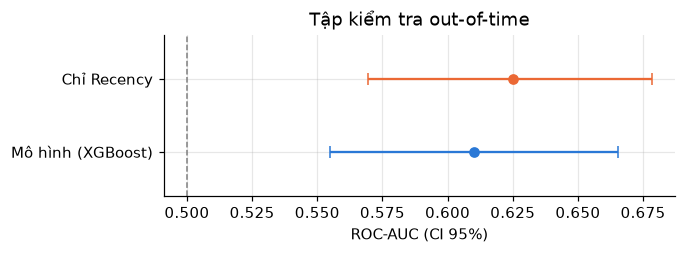

In [4]:
u = me["uncertainty_vs_recency_baseline"]
t = pd.DataFrame({"ROC-AUC": [u["model_auc"], u["baseline_auc"]],
                  "CI95 thấp": [u["model_auc_ci95"][0], u["baseline_auc_ci95"][0]], "CI95 cao": [u["model_auc_ci95"][1], u["baseline_auc_ci95"][1]]},
                 index=[f"Mô hình ({ts['model']})", "Chỉ Recency"])
fig, ax = plt.subplots(figsize=(6, 1.9))
for i, (name, r) in enumerate(t.iterrows()):
    ax.errorbar(r["ROC-AUC"], i, xerr=[[r["ROC-AUC"] - r["CI95 thấp"]], [r["CI95 cao"] - r["ROC-AUC"]]], fmt="o", color=C[i], capsize=4)
ax.axvline(0.5, color="gray", ls="--", lw=1); ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.set_ylim(-0.6, len(t) - 0.4)
ax.set_xlabel("ROC-AUC (CI 95%)"); ax.set_title("Tập kiểm tra out-of-time")
print(f"Chênh lệch AUC (mô hình − Recency): CI95 {u['difference_ci95']} | tỷ lệ lần bootstrap mô hình tốt hơn: {u['share_model_better']:.0%}")
t

**Nhận xét (từ số liệu trên):**
- Mô hình phân biệt tốt hơn ngẫu nhiên (CI 95% của AUC nằm hoàn toàn trên 0,5).
- Trên tập kiểm tra out-of-time, mô hình **chưa vượt được** đối chứng chỉ dùng Recency: khoảng tin cậy của chênh lệch chứa 0. Nhiều đặc trưng hành vi chưa thêm được thông tin dự báo đáng kể ngoài "khách mua gần đây đến mức nào".
- Nguyên nhân khả dĩ: lịch sử mỗi khách rất ngắn (đa số 1 đơn), cửa sổ kết quả chỉ ~8,6 ngày, tỷ lệ churn 96%.

### 1.3. Hiệu chỉnh xác suất (calibration)

ECE 0.414 | Brier mô hình 0.2230 vs Brier dự đoán hằng số 0.0364


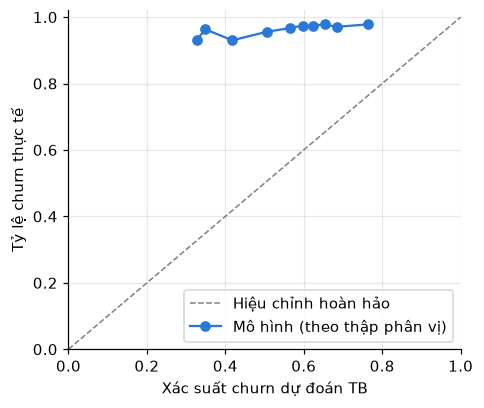

In [5]:
cal = pd.DataFrame(me["calibration"]["bins"])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Hiệu chỉnh hoàn hảo")
ax.plot(cal["mean_predicted"], cal["actual_rate"], "o-", color=C[0], label="Mô hình (theo thập phân vị)")
ax.set_xlabel("Xác suất churn dự đoán TB"); ax.set_ylabel("Tỷ lệ churn thực tế"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(loc="lower right")
c = me["calibration"]; print(f"ECE {c['expected_calibration_error']:.3f} | Brier mô hình {c['brier_model']:.4f} vs Brier dự đoán hằng số {c['brier_constant_base_rate']:.4f}")

Xác suất bị **đánh giá thấp có hệ thống** (hệ quả của cân bằng lớp), nên không dùng làm ngưỡng cảnh báo trực tiếp. Đây là căn cứ của cảnh báo theo thứ hạng (notebook 03, mục 1.1).

### 1.4. Độ ổn định theo thời gian (walk-forward)
Huấn luyện trên các mốc tuần trước, kiểm tra trên mốc tuần sau (cửa sổ mở rộng, nhãn 7 ngày, khách active 30 ngày).

AUC trung bình 0.5773 ± 0.0814 (min 0.5061, max 0.6483); vượt Recency ở 2/4 kỳ


,n_train,n_test,churn_rate_test,roc_auc,recency_only_roc_auc
2022-10-14,441,2280,0.9728,0.5061,0.5182
2022-10-21,2721,6961,0.9550,0.5075,0.5758
2022-10-28,9682,9718,0.9677,0.6483,0.6243
2022-11-04,19400,14115,0.9685,0.6472,0.6352


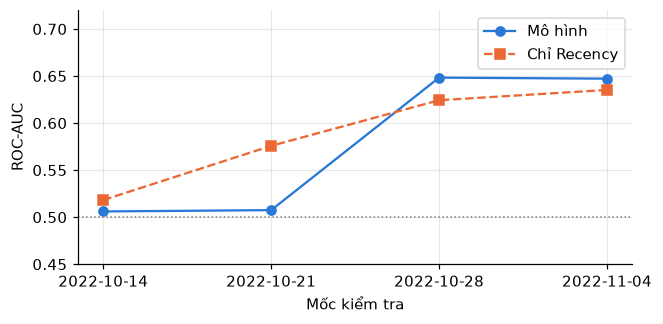

In [6]:
f = pd.DataFrame(me["walk_forward"]["folds"]).set_index("test_cutoff")
f.index = [i[:10] for i in f.index]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(f.index, f["roc_auc"], "o-", color=C[0], label="Mô hình"); ax.plot(f.index, f["recency_only_roc_auc"], "s--", color=C[1], label="Chỉ Recency")
ax.axhline(0.5, color="gray", lw=1, ls=":"); ax.set_ylabel("ROC-AUC"); ax.set_xlabel("Mốc kiểm tra"); ax.legend(); ax.set_ylim(0.45, 0.72)
s = wf["summary"]; print(f"AUC trung bình {s['roc_auc_mean']} ± {s['roc_auc_std']} (min {s['roc_auc_min']}, max {s['roc_auc_max']}); vượt Recency ở {s['beats_recency_only_in']}/{s['n_folds']} kỳ")
f[["n_train", "n_test", "churn_rate_test", "roc_auc", "recency_only_roc_auc"]]

### 1.5. Bài toán A — mua lặp lại sau đơn đầu tiên
Nhãn: khách có đặt thêm đơn trong W ngày sau đơn đầu không (chỉ giữ khách đủ W ngày theo dõi); đặc trưng chỉ từ đơn đầu.

In [7]:
pd.DataFrame(me["repeat_purchase"]).set_index("window_days")

,status,eligible_customers,positive_rate,best_model,label_session_gap_hours,label_positives_without_session_merge,label_positives_removed_by_session_merge,label_positives_next_purchase_within_24h,test_roc_auc,test_pr_auc
window_days,,,,,,,,,,
7,ok,14377,0.0531,Random Forest,8.0,939.0,175.0,0.1322,0.5433,0.0693
14,ok,9801,0.0774,Random Forest,8.0,862.0,103.0,0.0711,0.5563,0.1132
21,ok,6993,0.0908,XGBoost,8.0,687.0,52.0,0.0425,0.5331,0.1227
60,"Không đủ dữ liệu: cần >= 500 khách đủ điều kiện và >= 30 khách mua lại (hiện 18 khách,...",18,0.0556,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Định nghĩa "lần mua":** mỗi đơn trong dữ liệu chỉ có một sản phẩm, nên mua nhiều món một lúc tạo nhiều đơn cách nhau vài phút. Các đơn nối tiếp nhau cách ≤ 8 giờ được gộp thành **một lần mua**; nhãn "mua lại" chỉ tính khi có **lần mua mới**. Ngưỡng 8 giờ lấy từ điểm gãy của phân bố khoảng cách giữa hai đơn liên tiếp (bảng dưới).

Cột `label_positives_removed_by_session_merge`: số khách lẽ ra bị gán "mua lại" nếu không gộp, thực chất chỉ là cùng một lần mua nhiều món.

In [8]:
orders = fe.load_orders().sort_values(["customer_id", "order_time", "id"])
gap = (orders.groupby("customer_id")["order_time"].diff().dt.total_seconds() / 3600).dropna()
bins = [0, 1, 4, 8, 12, 24, 48, 72, 168, np.inf]
t = pd.cut(gap, bins).value_counts().sort_index()
pd.DataFrame({"số cặp đơn": t, "tỷ lệ": (t / t.sum()).round(3)}).rename_axis("khoảng cách (giờ)")

,số cặp đơn,tỷ lệ
khoảng cách (giờ),,
"(0.0, 1.0]",188,0.088
"(1.0, 4.0]",115,0.054
"(4.0, 8.0]",52,0.024
"(8.0, 12.0]",15,0.007
"(12.0, 24.0]",148,0.069
"(24.0, 48.0]",148,0.069
"(48.0, 72.0]",188,0.088
"(72.0, 168.0]",595,0.277
"(168.0, inf]",699,0.325


## 2. CV 6.2 — Đánh giá hiệu quả hỗ trợ ra quyết định
### 2.1. Cảnh báo có nhắm đúng đối tượng không?

In [9]:
d = de["data"]; rows = []
for key, label, metric, boot in (("risk_alerts", "Cảnh báo rủi ro (CRITICAL/HIGH)", "actual_churn_rate", "churn_rate_bootstrap"),
                                 ("opportunity_alerts", "Cảnh báo cơ hội (VIP/Tiềm năng, rủi ro thấp)", "actual_repurchase_rate", "repurchase_bootstrap")):
    a, b = de[key]["alerted"], de[key]["not_alerted"]; ci = de[key][boot]
    base = d["base_actual_churn_rate"] if metric == "actual_churn_rate" else d["base_actual_repurchase_rate"]
    rows.append({"Cảnh báo": label, "Chỉ số": "tỷ lệ churn thực tế" if metric == "actual_churn_rate" else "tỷ lệ mua lại thực tế",
                 "Số khách": a["customers"], "Nhóm được cảnh báo": a[metric], "CI95": f"[{ci['rate_ci95'][0]:.3f}; {ci['rate_ci95'][1]:.3f}]",
                 "Nhóm còn lại": b[metric], "Toàn bộ": base, "Lift": a[metric] / base, "CI95 lift": f"[{ci['lift_ci95'][0]:.2f}; {ci['lift_ci95'][1]:.2f}]"})
pd.DataFrame(rows).set_index("Cảnh báo").style.format({"Nhóm được cảnh báo": "{:.3f}", "Nhóm còn lại": "{:.3f}", "Toàn bộ": "{:.3f}", "Lift": "{:.2f}"})

,Chỉ số,Số khách,Nhóm được cảnh báo,CI95,Nhóm còn lại,Toàn bộ,Lift,CI95 lift
Cảnh báo,,,,,,,,
Cảnh báo rủi ro (CRITICAL/HIGH),tỷ lệ churn thực tế,426,0.979,[0.965; 0.991],0.959,0.962,1.02,[1.00; 1.03]
"Cảnh báo cơ hội (VIP/Tiềm năng, rủi ro thấp)",tỷ lệ mua lại thực tế,46,0.152,[0.056; 0.265],0.036,0.038,4.03,[1.54; 6.98]


**Nhận xét:**
- **Cảnh báo cơ hội** có giá trị rõ nhất: nhóm được chọn mua lại cao gấp nhiều lần mức chung, và cận dưới khoảng tin cậy của lift vẫn > 1. Tuy vậy nhóm nhỏ nên khoảng tin cậy rộng; không nên trích dẫn một con số lift duy nhất.
- **Cảnh báo rủi ro** chỉ cao hơn mức chung rất ít, vì gần như mọi khách (96%) đều không quay lại trong cửa sổ ngắn. Khi đó cảnh báo rủi ro chủ yếu giúp **ưu tiên thứ tự**, chưa phải phân biệt mạnh.

### 2.2. Theo mức cảnh báo và theo kịch bản

,customers,actual_churn_rate,actual_repurchase_rate,repurchase_lift
CRITICAL,2.0,1.0000,0.0000,0.00
HIGH,424.0,0.9788,0.0212,0.56
MEDIUM,1634.0,0.9645,0.0355,0.94
LOW,664.0,0.9458,0.0542,1.43


,name,customers,actual_repurchase_rate,repurchase_lift
KB1,Cứu vãn khẩn cấp,273,0.022,0.58
KB2,Win-back nhóm Rủi ro,942,0.0403,1.07
KB3,Giữ chân khách giá trị đang giảm tương tác,487,0.0308,0.81
KB4,Kích hoạt lại nhu cầu,358,0.0223,0.59
KB5,Tri ân & bán thêm,664,0.0542,1.43


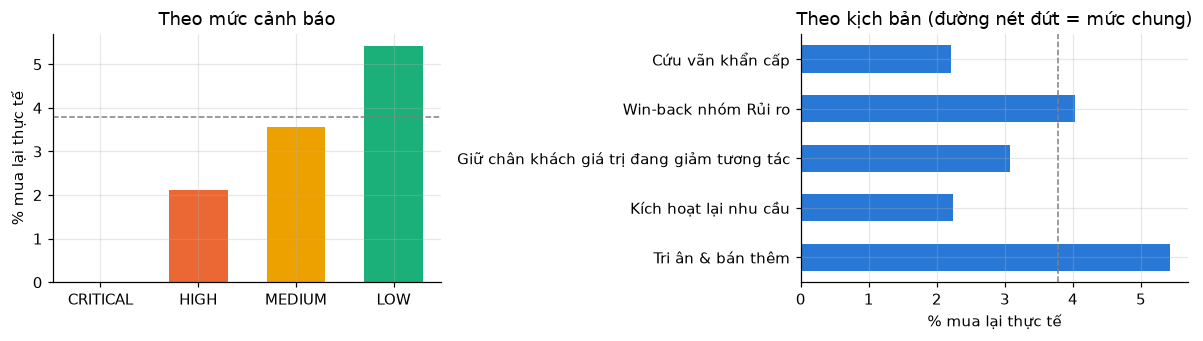

In [10]:
lv = pd.DataFrame(de["by_alert_level"]).T[["customers", "actual_churn_rate", "actual_repurchase_rate", "repurchase_lift"]]
st = pd.DataFrame(de["by_strategy"]).T[["name", "customers", "actual_repurchase_rate", "repurchase_lift"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(lv.index, lv["actual_repurchase_rate"].astype(float) * 100, color=[LEVEL_COLOR[k] for k in lv.index], width=0.6)
axes[0].axhline(d["base_actual_repurchase_rate"] * 100, color="gray", ls="--", lw=1); axes[0].set_ylabel("% mua lại thực tế"); axes[0].set_title("Theo mức cảnh báo")
axes[1].barh(st["name"][::-1], st["actual_repurchase_rate"].astype(float)[::-1] * 100, color=C[0], height=0.55)
axes[1].axvline(d["base_actual_repurchase_rate"] * 100, color="gray", ls="--", lw=1); axes[1].set_xlabel("% mua lại thực tế"); axes[1].set_title("Theo kịch bản (đường nét đứt = mức chung)")
plt.tight_layout(); display(lv); st

Tỷ lệ mua lại giảm dần từ LOW đến CRITICAL: thứ tự ưu tiên của DSS **khớp với hành vi thực tế**. Nhóm kịch bản KB5 (tri ân & bán thêm) có tỷ lệ mua lại cao nhất, đúng với mục tiêu khai thác cơ hội của kịch bản này.

### 2.3. Độ phủ của từng luật

In [11]:
pd.DataFrame(de["rule_coverage"]).set_index("rule_id")[["level", "strategy", "customers", "actual_churn_rate", "actual_repurchase_rate", "repurchase_lift"]]

,level,strategy,customers,actual_churn_rate,actual_repurchase_rate,repurchase_lift
rule_id,,,,,,
R01_VIP_CRITICAL,CRITICAL,KB1,2,1.0000,0.0000,0.00
R02_HIGH_CHURN,HIGH,KB1,271,0.9779,0.0221,0.59
R03_AT_RISK_MEDIUM_CHURN,HIGH,KB2,153,0.9804,0.0196,0.52
R04_AT_RISK_FLOOR,MEDIUM,KB2,789,0.9556,0.0444,1.17
R05_VIP_DECLINING,MEDIUM,KB3,77,0.9610,0.0390,1.03
R06_POTENTIAL_DECLINING,MEDIUM,KB3,410,0.9707,0.0293,0.77
R07_NEEDS_ATTENTION,MEDIUM,KB4,358,0.9777,0.0223,0.59
R08_UNKNOWN_MEDIUM_CHURN,MEDIUM,KB4,0,NaN,NaN,NaN
R09_VIP_LOYAL,LOW,KB5,23,0.8261,0.1739,4.60


### 2.4. Độ nhạy của ngưỡng (căn cứ chọn ngưỡng)

,customers,actual_churn_rate,churn_lift
top_percent,,,
5,137,0.9927,1.032
10,273,0.9780,1.016
20,552,0.9746,1.013
30,818,0.9756,1.014
40,1091,0.9753,1.014


,customers,actual_repurchase_rate,repurchase_lift
max_percentile,,,
10,38,0.1842,4.87
20,46,0.1522,4.02
30,190,0.1000,2.64
40,324,0.0802,2.12
50,518,0.0637,1.68


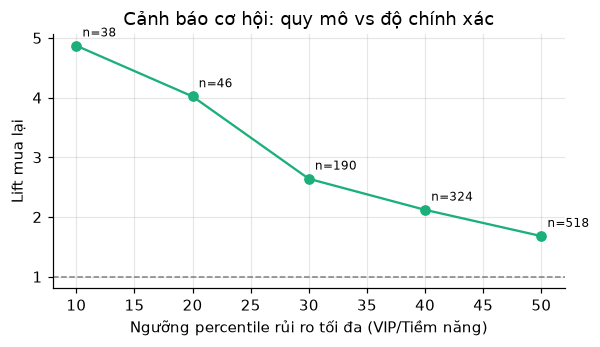

In [12]:
sens = de["threshold_sensitivity"]
r = pd.DataFrame(sens["risk_top_percent"]).set_index("top_percent"); o = pd.DataFrame(sens["opportunity_max_percentile"]).set_index("max_percentile")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(o.index, o["repurchase_lift"], "o-", color=C[2]); ax.axhline(1, color="gray", ls="--", lw=1)
for x, y, n in zip(o.index, o["repurchase_lift"], o["customers"]): ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("Ngưỡng percentile rủi ro tối đa (VIP/Tiềm năng)"); ax.set_ylabel("Lift mua lại"); ax.set_title("Cảnh báo cơ hội: quy mô vs độ chính xác")
display(r); o

Ngưỡng là **lựa chọn nghiệp vụ**, không có điểm tối ưu duy nhất: nới ngưỡng thì danh sách dài hơn nhưng lift giảm. Hệ thống đặt mặc định 20% (danh sách ngắn, độ chính xác cao). Nếu doanh nghiệp cần danh sách lớn hơn cho chiến dịch, ngưỡng 30% cho nhiều khách hơn đáng kể mà lift vẫn > 1 (xem bảng). Với cỡ nhóm nhỏ, chênh lệch lift giữa các ngưỡng gần nhau chưa đáng tin (khoảng tin cậy rộng, mục 2.1).

### 2.5. Xếp hạng khả năng mua lại (cumulative gains)

Top 10% danh sách bắt được 18.4% số khách mua lại (ngẫu nhiên: 10%)


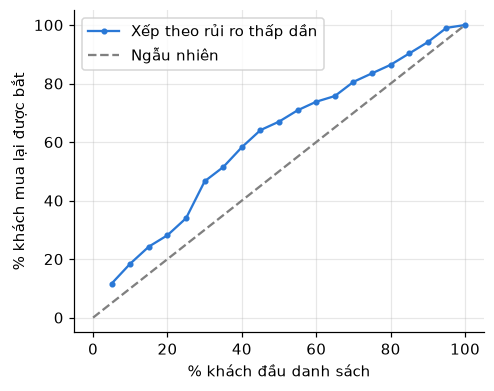

In [13]:
g = pd.DataFrame(de["repurchase_ranking"]["cumulative_gains"])
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.plot(g["population_share"] * 100, g["captured_share"] * 100, "o-", color=C[0], ms=3, label="Xếp theo rủi ro thấp dần")
ax.plot([0, 100], [0, 100], "--", color="gray", label="Ngẫu nhiên"); ax.set_xlabel("% khách đầu danh sách"); ax.set_ylabel("% khách mua lại được bắt"); ax.legend()
t10 = de["repurchase_ranking"]["top_10pct"]; print(f"Top 10% danh sách bắt được {t10['captured_share']:.1%} số khách mua lại (ngẫu nhiên: 10%)")

### 2.6. Độ ổn định của cảnh báo qua thời gian (walk-forward)
Ở mỗi tuần kiểm tra, xét top 10% rủi ro và 20% rủi ro thấp nhất (percentile tính trong tuần đó).

,top_churn_rate,base_churn_rate,top_churn_lift,bottom_repurchase_rate,base_repurchase_rate,bottom_repurchase_lift
Mốc,,,,,,
2022-10-14,0.9735,0.9728,1.001,0.0308,0.0272,1.13
2022-10-21,0.9505,0.9550,0.995,0.0491,0.0450,1.09
2022-10-28,0.9835,0.9677,1.016,0.0683,0.0323,2.11
2022-11-04,0.9844,0.9685,1.016,0.0588,0.0315,1.87


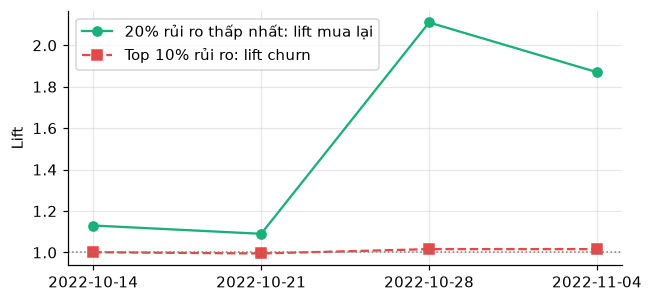

In [14]:
st = pd.DataFrame([{"Mốc": x["test_cutoff"][:10], **x["dss_alerts"]} for x in wf["folds"] if x.get("status") == "ok"]).set_index("Mốc")
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(st.index, st["bottom_repurchase_lift"], "o-", color=C[2], label="20% rủi ro thấp nhất: lift mua lại")
ax.plot(st.index, st["top_churn_lift"], "s--", color=C[7], label="Top 10% rủi ro: lift churn")
ax.axhline(1, color="gray", lw=1, ls=":"); ax.set_ylabel("Lift"); ax.legend()
st[["top_churn_rate", "base_churn_rate", "top_churn_lift", "bottom_repurchase_rate", "base_repurchase_rate", "bottom_repurchase_lift"]]

Nhóm rủi ro thấp nhất mua lại nhiều hơn mức chung ở **cả 4 tuần**, rõ nhất ở 2 tuần cuối. Lift của top 10% rủi ro dao động quanh 1 do tỷ lệ churn nền rất cao.

### 2.7. Case study (mã khách đã che)

In [15]:
pd.DataFrame(de["case_studies"]).set_index("title").T

title,VIP có nguy cơ rời bỏ cao,Khách tiềm năng có xu hướng mua lại,Khách nhóm Rủi ro (chưa có/ít đơn thành công)
display_id,KH_GLORW7RLXR,KH_VOTNSFGDBJ,KH_VSOFGPPCYO
segment,VIP,VIP,Rủi ro
recency_days,8.3,5.5,48.3
completed_orders,2,2,0
total_orders,2,2,1
monetary,340000.0,1300000.0,0.0
channel,TikTok Shop,Facebook Fanpage,Facebook Fanpage
region,Miền Nam,Miền Nam,Miền Bắc
churn_prob_pct,72.82,20.67,84.28
risk_percentile,92.47,0.04,99.93


## 3. Giới hạn của đánh giá

In [16]:
for x in de["limitations"]: print("•", x)
print("• Mô hình churn chưa vượt đối chứng Recency có ý nghĩa thống kê trên tập kiểm tra out-of-time (mục 1.2).")
print("• Dữ liệu từ một doanh nghiệp, khoảng 5 tháng; cần kiểm chứng lại khi có thêm dữ liệu.")

• Đo khả năng nhắm đúng đối tượng, chưa đo hiệu quả nhân quả của hành động CSKH (cần thử nghiệm A/B).
• Nhóm cảnh báo khách tiềm năng nhỏ nên khoảng tin cậy rộng (xem repurchase_bootstrap).
• Cửa sổ kết quả ngắn (vài ngày) vì dữ liệu chỉ kéo dài khoảng 5 tháng.
• Ngưỡng cảnh báo cơ hội (20%) được chọn sau khi xem kết quả trên chính tập kiểm tra này, nên lift ở đây có thể lạc quan; ước lượng độc lập hơn là đánh giá walk-forward (không chỉnh ngưỡng theo từng kỳ).
• Mô hình K-Means được huấn luyện trên RFM của toàn bộ giai đoạn (gồm cả sau mốc cắt), chỉ việc gán phân khúc cho khách kiểm tra mới dùng số liệu tại mốc cắt.
• Mô hình churn chưa vượt đối chứng Recency có ý nghĩa thống kê trên tập kiểm tra out-of-time (mục 1.2).
• Dữ liệu từ một doanh nghiệp, khoảng 5 tháng; cần kiểm chứng lại khi có thêm dữ liệu.
